In [1]:
# Instalação do Biopython (no Colab ele não vem instalado). Rode esta célula primeiro.
!pip install -q biopython


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# Quem é parente de quem? A árvore da vida pelo DNA

**Ambientes em Computação — UFMG · Projeto final**

Neste notebook comparamos o gene mitocondrial **citocromo b (CYTB)** de 15 espécies, usando um algoritmo de alinhamento
**implementado do zero** (Needleman-Wunsch), e a partir dele construímos uma **matriz de distância**, um **heatmap** e uma **árvore filogenética**.

**Roteiro do notebook**
1. Introdução
2. Dados (download do NCBI)
3. Algoritmo (Needleman-Wunsch)
4. Análise (distâncias, heatmap, árvore)
5. Complexidade (tempo × tamanho)
6. Conclusões e limitações

## 1. Introdução

### A pergunta central
> **Dá para descobrir quem é parente de quem apenas comparando o DNA das espécies?**

Se dois animais têm um ancestral comum recente, seus DNAs tiveram pouco tempo para acumular diferenças. Quanto mais distante o parentesco, mais diferenças acumuladas.
Então, *medir o quanto dois DNAs se parecem* é uma forma de medir parentesco.

### DNA como um "texto"
O DNA pode ser visto como um texto escrito com apenas **4 letras**: **A, C, G, T**. Um gene é como uma frase longa nesse alfabeto.
O gene que usaremos, o **CYTB** (citocromo b), fica nas mitocôndrias (as "usinas de energia" das células) e tem cerca de **1.140 letras**.
Ele é muito usado em estudos de parentesco porque todos os vertebrados o possuem, e ele muda devagar o bastante para ser comparável.

### O que é "alinhar" duas sequências?
Imagine duas frases quase iguais:

```
O GATO COMEU O PEIXE
O GATO COMEU - PEIXE      <- faltou uma palavra; marcamos o "buraco" com '-'
```

**Alinhar** é colocar as duas sequências lado a lado, inserindo "buracos" (*gaps*) quando necessário, de modo que as partes parecidas fiquem na mesma coluna.
Em seguida, contamos quantas colunas são iguais (**identidade**). No DNA, um buraco representa uma inserção ou remoção de letras ao longo da evolução, e uma coluna diferente representa uma mutação.

O algoritmo de **Needleman-Wunsch** encontra o *melhor* alinhamento possível de ponta a ponta (alinhamento **global**), usando uma pontuação:
**+ para letras iguais (match), − para letras diferentes (mismatch) e − para buracos (gap)**.

In [2]:
# ===== Importações e configurações gerais =====
import os, io, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from Bio import Entrez, SeqIO, Align
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from scipy.cluster.hierarchy import linkage, dendrogram, to_tree
from scipy.spatial.distance import squareform
from IPython.display import display

# >>> EDITE AQUI: o NCBI pede um e-mail de contato para quem usa a API <<<
ENTREZ_EMAIL = "seu_email@exemplo.com"
Entrez.email = ENTREZ_EMAIL

# Pastas de saída (no Colab aparecem no painel de arquivos à esquerda)
PASTA_DADOS = "dados"
PASTA_FIGURAS = "figuras"
os.makedirs(PASTA_DADOS, exist_ok=True)
os.makedirs(PASTA_FIGURAS, exist_ok=True)

# Estilo dos gráficos: fonte grande e fundo claro, pensando em projetor
sns.set_theme(style="white", context="talk")
plt.rcParams.update({
    "font.size": 16, "axes.titlesize": 20, "axes.labelsize": 17,
    "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 14,
    "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
})

# Cores consistentes por grupo (paleta amigável a daltônicos)
COR_GRUPO = {
    "Primatas":      "#0072B2",
    "Carnívoros":    "#D55E00",
    "Ungulados e baleias": "#009E73",
    "Roedor":        "#CC79A7",
    "Ave (grupo externo)":   "#B8860B",
    "Peixe (grupo externo)": "#555555",
}

## 2. Dados: baixando o gene CYTB do NCBI

Usamos o **Biopython (`Bio.Entrez`)** para baixar os registros do banco `nucleotide` do NCBI (GenBank).

**Como os accession numbers foram encontrados:** buscando no NCBI (`Entrez.esearch`) por organismo + gene CYTB + comprimento aproximado de 1.100–1.200 pb, e conferindo o título do registro (preferimos "complete cds"). Nenhum código foi inventado.
Para humano, gorila, camundongo e peixe-zebra não usamos um registro curto só do CYTB, e sim o **genoma mitocondrial de referência (RefSeq, `NC_...`)**, extraindo o trecho do CYTB pela anotação do próprio registro.

Cada sequência é **validada**: comprimento entre 1.080 e 1.200 bases e quase só letras A/C/G/T.
Se o NCBI estiver fora do ar (ou menos de 12 espécies forem baixadas), o notebook usa automaticamente um **conjunto menor embutido (Plano B)** e avisa claramente.

In [3]:
# Tabela de espécies: (nome popular, nome científico, grupo, accession no NCBI)
ESPECIES = [
    ("Humano",        "Homo sapiens",               "Primatas",              "NC_012920.1"),   # genoma mito de referência
    ("Chimpanzé",     "Pan troglodytes",            "Primatas",              "X93338.1"),
    ("Gorila",        "Gorilla gorilla gorilla",    "Primatas",              "NC_011120.1"),   # genoma mito de referência
    ("Orangotango",   "Pongo abelii",               "Primatas",              "U38274.1"),
    ("Macaco-rhesus", "Macaca mulatta",             "Primatas",              "U38272.1"),
    ("Cachorro",      "Canis lupus familiaris",     "Carnívoros",            "EU352854.1"),
    ("Lobo",          "Canis lupus",                "Carnívoros",            "AY928668.1"),
    ("Gato",          "Felis catus",                "Carnívoros",            "KU253483.1"),
    ("Leão",          "Panthera leo",               "Carnívoros",            "AF384818.1"),
    ("Vaca",          "Bos taurus",                 "Ungulados e baleias",   "PP997875.1"),
    ("Hipopótamo",    "Hippopotamus amphibius",     "Ungulados e baleias",   "U07565.1"),
    ("Baleia-azul",   "Balaenoptera musculus",      "Ungulados e baleias",   "KJ586852.1"),
    ("Camundongo",    "Mus musculus",               "Roedor",                "NC_005089.1"),   # genoma mito de referência
    ("Galinha",       "Gallus gallus",              "Ave (grupo externo)",   "AB044986.1"),
    ("Peixe-zebra",   "Danio rerio",                "Peixe (grupo externo)", "NC_002333.2"),   # genoma mito de referência
]
GRUPO_DE = {nome: grupo for nome, _, grupo, _ in ESPECIES}
CIENT_DE = {nome: cient for nome, cient, _, _ in ESPECIES}

COMPRIMENTO_MIN, COMPRIMENTO_MAX = 1080, 1200   # "próximo de 1.140 bases"
MIN_ESPECIES = 12      # abaixo disso, usamos o Plano B
FORCAR_PLANO_B = False # coloque True para testar o Plano B mesmo com internet


def baixar_cytb(accession, tentativas=3):
    """Baixa um registro do NCBI e devolve a sequência do CYTB (str).
    - Se o registro tiver uma feature CDS de CYTB (caso dos genomas mitocondriais), extrai só esse trecho.
    - Caso contrário (registros que já são só o gene), usa a sequência inteira."""
    ultimo_erro = None
    for t in range(tentativas):
        try:
            h = Entrez.efetch(db="nucleotide", id=accession, rettype="gb", retmode="text")
            reg = SeqIO.read(h, "genbank")
            h.close()
            time.sleep(0.4)                       # o NCBI limita a ~3 requisições por segundo
            for f in reg.features:
                if f.type == "CDS":
                    txt = (f.qualifiers.get("gene", [""])[0] + " " + f.qualifiers.get("product", [""])[0]).lower()
                    if any(k in txt for k in ("cytb", "cyt b", "cytochrome b", "cob")):
                        return str(f.extract(reg.seq)).upper()
            return str(reg.seq).upper()
        except Exception as e:                    # rede instável, limite de uso, etc.
            ultimo_erro = e
            time.sleep(1.5 * (t + 1))
    raise RuntimeError(f"falha ao baixar {accession}: {ultimo_erro}")


def validar(seq):
    """Valida comprimento (~1.140 pb) e composição (A/C/G/T). Devolve (ok, motivo)."""
    if not (COMPRIMENTO_MIN <= len(seq) <= COMPRIMENTO_MAX):
        return False, f"comprimento {len(seq)} fora de {COMPRIMENTO_MIN}-{COMPRIMENTO_MAX}"
    frac_acgt = sum(seq.count(b) for b in "ACGT") / len(seq)
    if frac_acgt < 0.99:
        return False, f"só {frac_acgt:.1%} das letras são A/C/G/T"
    return True, "OK"


# ---------- Download com validação ----------
baixadas, status = {}, {}
if not FORCAR_PLANO_B:
    for nome, cient, grupo, acc in ESPECIES:
        try:
            s = baixar_cytb(acc)
            ok, motivo = validar(s)
            status[nome] = motivo
            if ok:
                baixadas[nome] = s
        except Exception as e:
            status[nome] = f"ERRO: {e}"[:80]
        print(f"{nome:14s} {acc:12s} -> {status[nome]}")
print(f"\n{len(baixadas)} de {len(ESPECIES)} espécies baixadas e validadas.")

Humano         NC_012920.1  -> OK


Chimpanzé      X93338.1     -> OK


Gorila         NC_011120.1  -> OK


Orangotango    U38274.1     -> OK


Macaco-rhesus  U38272.1     -> OK


Cachorro       EU352854.1   -> OK


... (5 outputs left out)

Baleia-azul    KJ586852.1   -> OK


Camundongo     NC_005089.1  -> OK


Galinha        AB044986.1   -> OK


Peixe-zebra    NC_002333.2  -> OK

15 de 15 espécies baixadas e validadas.


### Plano B: sequências embutidas
Esta célula só é usada se o NCBI estiver inacessível. Contém **9 espécies** (humano, chimpanzé, gorila, cachorro, gato, vaca, baleia-azul, galinha e peixe-zebra), copiadas das mesmas sequências do NCBI baixadas durante o desenvolvimento do notebook (accession no cabeçalho de cada uma).

In [4]:
# Plano B: sequências embutidas (FASTA). Só será usado se o download falhar.
FASTA_PLANO_B = """
>NC_012920.1 Humano | Homo sapiens | CYTB
ATGACCCCAATACGCAAAACTAACCCCCTAATAAAATTAATTAACCACTCATTCATCGACCTCCCCACCCCATCCAACAT
CTCCGCATGATGAAACTTCGGCTCACTCCTTGGCGCCTGCCTGATCCTCCAAATCACCACAGGACTATTCCTAGCCATGC
ACTACTCACCAGACGCCTCAACCGCCTTTTCATCAATCGCCCACATCACTCGAGACGTAAATTATGGCTGAATCATCCGC
TACCTTCACGCCAATGGCGCCTCAATATTCTTTATCTGCCTCTTCCTACACATCGGGCGAGGCCTATATTACGGATCATT
TCTCTACTCAGAAACCTGAAACATCGGCATTATCCTCCTGCTTGCAACTATAGCAACAGCCTTCATAGGCTATGTCCTCC
CGTGAGGCCAAATATCATTCTGAGGGGCCACAGTAATTACAAACTTACTATCCGCCATCCCATACATTGGGACAGACCTA
GTTCAATGAATCTGAGGAGGCTACTCAGTAGACAGTCCCACCCTCACACGATTCTTTACCTTTCACTTCATCTTGCCCTT
CATTATTGCAGCCCTAGCAACACTCCACCTCCTATTCTTGCACGAAACGGGATCAAACAACCCCCTAGGAATCACCTCCC
ATTCCGATAAAATCACCTTCCACCCTTACTACACAATCAAAGACGCCCTCGGCTTACTTCTCTTCCTTCTCTCCTTAATG
ACATTAACACTATTCTCACCAGACCTCCTAGGCGACCCAGACAATTATACCCTAGCCAACCCCTTAAACACCCCTCCCCA
CATCAAGCCCGAATGATATTTCCTATTCGCCTACACAATTCTCCGATCCGTCCCTAACAAACTAGGAGGCGTCCTTGCCC
TATTACTATCCATCCTCATCCTAGCAATAATCCCCATCCTCCATATATCCAAACAACAAAGCATAATATTTCGCCCACTA
AGCCAATCACTTTATTGACTCCTAGCCGCAGACCTCCTCATTCTAACCTGAATCGGAGGACAACCAGTAAGCTACCCTTT
TACCATCATTGGACAAGTAGCATCCGTACTATACTTCACAACAATCCTAATCCTAATACCAACTATCTCCCTAATTGAAA
ACAAAATACTCAAATGGGCCT
>X93338.1 Chimpanzé | Pan troglodytes | CYTB
ATGACCCCAACACGCAAAATTAACCCACTAATAAAATTAATTAATCACTCATTTATCGACCTCCCCACCCCATCCAACAT
TTCCGCATGATGGAACTTCGGCTCCCTTCTCGGCGCCTGCCTAATCCTTCAAATCACCACAGGATTATTCCTAGCCATAC
ACTACTCACCAGACGCCTCAACCGCCTTCTCGTCGATCGCCCACATCACCCGAGACGTAAACTATGGTTGGATCATCCGC
TACCTTCACGCCAATGGCACCTCAATATTTTTTATCTGCCTCTTCCTACACATCGGTCGAGGCCTATATTACGGCTCATT
TCTCTACCTAGAAACCTGAAACATTGGCATCATCCTCTTGCTCACAACCATAGCAACAGCCTTTATGGGCTATGTCCTCC
CATGAGGCCAAATATCCTTCTGAGGAGCCACAGTAATTACAAACCTACTATCCGCCATCCCGTATATCGGAACAGACCTG
GTCCAATGAGTCTGAGGAGGCTACTCAGTAGACAGCCCTACCCTCACACGATTCTTCACCTTCCACTTCATCTTACCCTT
CATTATCACAGCCCTAACAACACTTCATCTCCTATTCTTACACGAAACAGGATCAAATAACCCCCTAGGAATCACCTCCC
ACTCCGACAAAATTACCTTCCACCCCTACTACACAATCAAAGATATCCTTGGTTTATTCCTTTTCCTCCTTATCCTAATG
ACATTAACACTATTCTCACCAGACCTCCTAGGCGATCCAGACAACTACACCCTAGCTAACCCCCTAAACACCCCACCCCA
CATTAAACCCGAGTGATACTTTCTATTTGCCTACACAATTCTCCGATCCATCCCCAACAAACTAGGAGGTGTCCTCGCCT
TACTGCTATCTATCCTGATCCTAGCAGCAATCCCTGTCCTCCATACATCCAAACAACAAAGCATAATATTCCGCCCACTA
AGCCAACTGCTTTACTGACTCCTAGCCGCAGACCTCCTTATCCTAACCTGAATCGGAGGGCAACCAGTAGGCTACCCCTT
CATCACCATCGGACAAGCAGCATCCGCATTATACTTCACAACAATCCTAATCCTAATACCAATTACTTCCCTAATCGAAA
ACAAAATACTTGAATGAACC
>NC_011120.1 Gorila | Gorilla gorilla gorilla | CYTB
ATGACCCCTATACGCAAAACTAACCCACTAGCAAAACTAATTAACCACTCATTCATTGACCTCCCTACCCCGTCCAACAT
CTCCACATGATGAAACTTCGGCTCACTCCTTGGTGCCTGCTTAATCCTTCAAATCACCACAGGGCTATTCCTAGCCATAC
ACTACTCACCTGATGCCTCAACCGCCTTCTCATCAATCGCCCACATCACCCGAGATGTAAACTATGGCTGAACCATCCGC
TACCTCCACGCTAACGGCGCCTCAATATTCTTCATTTGCCTCTTTCTACACATCGGCCGGGGCCTATACTACGGCTCATT
TCTCCACCAAGAAACCTGAAACATCGGCATCATCCTCCTACTCACAACCATAGCAACAGCCTTCATAGGCTATGTCCTCC
CATGAGGCCAAATATCCTTCTGAGGGGCCACAGTAATCACAAACTTGCTATCCGCCATCCCGTACATCGGAACAGATCTA
GTCCAATGAGTTTGAGGTGGTTACTCAGTAGATAGCCCTACCCTTACACGATTCTTTACCTTCCACTTTATCCTACCCTT
CATTATCACAGCCCTAACAACCCTCCATCTCCTATTTCTACACGAAACAGGATCAAACAACCCTCTAGGCATCCCCTCCC
ACTCTGACAAAATCACCTTCCACCCCTACTACACAATCAAAGACATCCTAGGCCTATTCTTCTTTCTCCTGACCTTGATA
ACATTAACACTATTCTCACCAGACCTCCTAGGAGACCCAGACAACTACACTTTAGCCAACCCCCTAAACACCCCACCCCA
CATCAAACCCGAATGATATTTCCTATTTGCCTACGCAATTCTCCGATCTGTCCCCAATAAACTAGGAGGCGTCTTAGCTC
TATTACTATCCATTCTCATCCTAACAATAATTCCTATTCTCCACATATCCAAACAACAAAGCATAATATTCCGCCCATTA
AGCCAACTACTCTACTGATTCCTAATCGCAAACCTCTTCACCCTAACCTGAATCGGAGGACAACCAGTAAGCTACCCCTT
CATTACCATTGGGCAAGTAGCATCCGTACTATACTTCACGACAATCCTATTCCTGATACCAATCACATCCCTGATCGAAA
ACAAAATACTCAAATGAACCT
>EU352854.1 Cachorro | Canis lupus familiaris | CYTB
ATGACCAACATTCGAAAAACCCACCCACTAGCCAAAATTGTTAATAACTCATTCATTGACCTCCCAGCGCCGTCTAACAT
CTCTGCTTGATGGAACTTCGGATCCTTACTAGGAGTATGCTTGATTCTACAGATTCTAACAGGTTTGTTCTTAGCTATGC
ACTATACATCGGACACAGCCACAGCTTTTTCATCAGTCACGCACATCTGCCGAGACGTTAACTACGGCTGAATTATCCGC
TATATGCACGCAAATGGCGCTTCCATATTCTTTATCTGCCTATTCCTACATGTAGGACGAGGCCTATATTACGGATCCTA
TGTATTCATAGAAACATGAAACATTGGAATTGTACTATTATTCGCAACCATAGCCACAGCATTCATGGGCTATGTACTAC
CATGAGGACAAATATCATTTTGAGGAGCAACTGTAATCACTAATCTTCTCTCTGCCATCCCTTATATCGGAACTGACTTA
GTAGAATGGATCTGAGGCGGCTTCTCAGTGGACAAAGCAACCCTAACACGATTCTTTGCATTCCATTTCATCCTCCCTTT
CATCATCGCAGCTCTAGCAATAGTACACCTCCTATTTCTACACGAAACCGGATCCAACAACCCTTCAGGAATCACATCAG
ACTCAGACAAAATTCCATTTCACCCTTACTACACAATCAAGGATATCCTAGGAGCCTTACTCCTACTCCTAATCCTAATA
TCACTAGTTTTATTTTCACCTGACCTATTAGGAGACCCAGATAACTACACCCCTGCAAACCCCCTAAACACCCCTCCACA
TATTAAACCTGAGTGGTATTTTCTATTCGCCTATGCTATCCTACGATCCATTCCTAATAAATTAGGAGGTGTACTCGCCC
TAGTATTCTCCATCCTAATCTTGACATTCATTCCACTCCTCCACACATCTAAGCAACGCAGCATAATATTCCGGCCCCTT
AGCCAATGCCTATTCTGACTTTTAGTCGCCGATCTTCTCACTTTAACATGAATTGGAGGACAACCAGTTGAACACCCTTT
CATCATTATCGGACAAGTCGCTTCAATCTTATATTTCACCATCTTATTGATCCTAATACCAACAGTTAGCGTTATCGAAA
ACAACCTTCTAAAATGAAGA
>KU253483.1 Gato | Felis catus | CYTB
ATGACCAACATTCGAAAATCATACCCCCTTACCAAAATTATTAATCACTCATTCATCGACCTACCCGCCCCATCTAACAT
CTCAGCATGATGAAACTTCGGCTCCCTTCTAGGAGTCTGCCTAATCTTACAAATCCTCACCGGCCTCTTTTTGGCCATAC
ACTACACATCAGACACAATAACCGCCTTTTCATCAGTTACCCACATCTGTCGCGACGTTAATTATGGCTGAATCATCCGA
TATTTACACGCCAACGGAGCTTCTATATTCTTTATCTGCCTGTACATACATGTAGGACGGGGAATATACTACGGCTCCTA
CACCTTCTCAGAGACATGAAACATTGGAATCATACTATTATTTACAGTCATAGCCACAGCTTTTATGGGATACGTCCTAC
CATGAGGCCAAATGTCCTTCTGAGGAGCAACCGTAATCACTAACCTCCTGTCAGCAATTCCATACATCGGGACTGAACTA
GTAGAATGGATCTGAGGGGGCTTCTCAGTAGACAAAGCCACCCTAACACGATTCTTCGCCTTCCACTTCATCCTTCCATT
CATTATCTCAGCCTTAGCAGCAGTACACCTCTTATTCCTTCATGAAACAGGATCTAACAACCCCTCAGGAATTACATCCG
ATTCAGACAAAATCCCATTCCACCCATACTATACAATCAAAGACATCCTAGGTCTTCTAGTACTAGTTTTAACACTCATA
CTACTCGTCCTATTTTCACCAGACCTGCTAGGAGACCCAGACAACTACATCCCAGCCAACCCTTTAAATACCCCTCCCCA
TATTAAACCTGAATGATACTTCCTATTCGCATACGCAATTCTCCGATCCATCCCCAACAAACTAGGAGGAGTCCTAGCCC
TAGTACTCTCCATCCTAGTACTAGCAATCATTCCAATCCTCCACACCTCCAAACAACGAGGAATAATGTTTCGACCACTA
AGCCAATGTCTATTCTGACTCCTAGTAGCGGATCTCCTAACCCTAACATGAATCGGTGGCCAACCTGTAGAACATCCATT
CATCACCATCGGCCAACTAGCCTCCATCCTATATTTCTCAACCCTCCTAATCCTAATACCCATCTCAGGCATTATTGAAA
ACCGTCTACTCAAATGAAGA
>PP997875.1 Vaca | Bos taurus | CYTB
ATGACTAACATTCGAAAGTCCCACCCACTAATAAAAATTGTAAACAATGCATTCATCGACCTTCCAGCCCCATCAAACAT
TTCATCATGATGAAATTTCGGTTCCCTCCTGGGAATCTGCCTAATCCTACAAATCCTCACAGGCCTATTCCTAGCAATAC
ACTACACATCCGACACAACAACAGCATTCTCCTCTGTTACCCATATCTGCCGAGACGTGAACTACGGCTGAATCATCCGA
TACATACACGCAAACGGAGCTTCAATGTTTTTTATCTGCTTATATATGCACGTAGGACGAGGCTTATATTACGGGTCTTA
CACTTTTCTAGAAACATGAAATATTGGAGTAATCCTTCTGCTCACAGTAATAGCCACAGCATTTATAGGATACGTCCTAC
CATGAGGACAAATATCATTCTGAGGAGCAACAGTCATCACCAACCTCTTATCAGCAATCCCATACATCGGCACAAATTTA
GTCGAATGAATCTGAGGCGGATTCTCAGTAGACAAAGCAACCCTTACCCGATTCTTCGCTTTCCATTTTATCCTTCCATT
TATCATCATAGCAATTGCCATAGTCCACCTACTATTCCTCCACGAAACAGGCTCCAACAACCCAACAGGAATTTCCTCAG
ACGTAGACAAAATCCCATTCCACCCCTACTATACCATTAAGGACATCTTAGGGGCCCTCTTACTAATTCTAGCTCTAATA
CTACTAGTACTATTCGCACCCGACCTCCTCGGAGACCCAGATAACTACACCCCAGCCAATCCACTCAACACACCCCCTCA
CATCAAACCCGAGTGATACTTCTTATTTGCATACGCAATCTTACGATCAATCCCCAACAAACTAGGAGGAGTACTAGCCC
TAGCCTTCTCTATCCTAATTCTTGCTCTAATCCCCCTACTACACACCTCCAAACAACGAAGCATAATATTCCGACCACTC
AGCCAATGCCTATTCTGAGCCCTAGTAGCAGACCTACTGACACTCACATGAATTGGAGGACAACCAGTCGAACACCCATA
TATCACCATCGGACAACTAGCATCTGTCCTATACTTTCTCCTCATCCTAGTGCTAATACCAACGGCCGGCACAATCGAAA
ACAAATTACTAAAATGAAGA
>KJ586852.1 Baleia-azul | Balaenoptera musculus | CYTB
ATGACCAACATCCGAAAAACACACCCACTAATAAAAATCATCAACGATGCATTCATTGATCTCCCTACCCCATCAAACAT
CTCCTCATGATGAAACTTCGGCTCCCTACTCGGCCTCTGCTTAATTGTACAAATCCTAACAGGCCTATTCCTAGCAATAC
ACTATACACCAGACACAATAACCGCCTTCTCATCAGTCACACATATTTGCCGAGACGTAAACTATGGCTGAGTTATTCGG
TACTTACATGCAAACGGAGCCTCCATATTCTTCATCTGCCTCTACGCCCACATGGGACGAGGTCTATACTACGGCTCCCA
CGCTTTTCGAGAAACATGAAATATTGGAGTTATTCTACTATTCACGGTCATAGCCACTGCATTCGTAGGCTACGTCCTGC
CCTGAGGACAAATATCATTCTGAGGCGCAACCGTCATCACCAACCTCCTATCAGCAATCCCATACATTGGTACTACCCTA
GTCGAATGAATCTGAGGCGGTTTTTCTGTGGATAAAGCAACACTAACACGCTTCTTTGCCTTCCACTTCATTCTCCCCTT
CATCATTATAGCATTAGCAATCGTCCACCTCATCTTCCTTCACGAAACAGGATCCAACAACCCCACAGGTATCCCATCTG
ACATAGATAAAATTCCATTCCACCCCTACTACACAATTAAAGACATTCTAGGCGCCCTACTACTAATCCTAACCCTACTA
ATATTAACTCTATTTGCACCCGACTTACTCGGAGACCCAGACAACTACACCCCAGCAAACCCACTCAGTACCCCAGCACA
CATTAAACCAGAGTGATATTTCCTATTTGCATATGCAATCCTACGATCAATCCCCAACAAATTAGGTGGAGTCTTAGCCC
TACTACTCTCAATCCTAGTCCTAGCCCTAATCCCAATACTCCACACATCCAAACAACGAAGCATAATATTCCGACCCTTT
AGCCAATTCCTGTTTTGAGTACTGGTCGCAGACCTACTCACCCTAACGTGGATCGGCGGCCAACCCGTAGAACACCCCTA
TGTAATTGTAGGCCAACTCGCATCCATCCTTTACTTCCTCTTAATTCTAGTGTTAATACCAGTAACTAGTCTTATCGAAA
ATAAACTTATAAAATGAAGA
>AB044986.1 Galinha | Gallus gallus | CYTB
ATGGCACCCAACATTCGAAAATCCCACCCCCTACTAAAAATAATTAACAACTCCCTAATCGACCTCCCAGCCCCATCCAA
CATCTCTGCTTGATGAAATTTCGGCTCCCTATTAGCAGTCTGCCTCATGACCCAAATCCTCACCGGCCTACTACTAGCCA
TGCACTACACAGCAGACACTTCCCTAGCCTTCTCCTCCGTAGCCCACACTTGCCGGAACGTACAATACGGCTGACTCATC
CGGAATCTCCACGCAAACGGCGCCTCATTCTTCTTCATCTGTATCTTCCTTCACATCGGACGAGGCCTATACTACGGCTC
CTACCTCTACAAGGAAACCTGAAACACAGGAGTAATCCTCCTCCTCACACTCATAGCCACCGCCTTTGTGGGCTATGTTC
TCCCATGGGGCCAAATATCATTCTGAGGGGCCACCGTTATCACAAACCTATTCTCAGCAATTCCCTACATTGGACACACC
CTAGTAGAGTGAGCCTGAGGGGGATTTTCAGTCGACAACCCAACCCTTACCCGATTTTTCGCCTTACACTTCCTCCTCCC
CTTTGCAATCGCAGGTATTACTATCATCCACCTCACCTTCCTACACGAATCAGGCTCAAACAACCCCCTAGGCATCTCAT
CCGACTCTGACAAAATTCCATTTCACCCATACTACTCCTTCAAAGACATTCTGGGCTTAACTCTCATACTCACCCCATTC
CTAACACTAGCCCTATTCTCCCCCAACCTCCTAGGAGACCCAGAAAACTTCACCCCAGCAAACCCACTAGTAACCCCCCC
ACATATCAAACCAGAATGATATTTTCTATTCGCCTATGCCATCCTACGCTCCATCCCCAACAAACTTGGAGGTGTACTAG
CCCTAGCAGCCTCAGTCCTCATCCTCTTCCTAATCCCCTTCCTCCACAAATCTAAACAACGAACAATAACCTTCCGACCA
CTCTCCCAAACCCTATTCTGACTTCTAGTAGCCAACCTTCTTATCCTAACCTGAATCGGAAGCCAACCAGTAGAACACCC
CTTCATCATCATTGGCCAAATAGCATCCCTCTTTTACTTCACCATCCTACTTATCCTCTTCCCCACAATCGGAACACTAG
AAAACAAAATACTCAACTACTAA
>NC_002333.2 Peixe-zebra | Danio rerio | CYTB
ATGACAAGCCTGCGAAAAACACACCCAGTTTTAAAAATCGCTAATGACGCATTAGTTGATTTGCCAACGCCACTAAATAT
TTCAGCGTGATGAAATTTTGGATCTCTCCTTGGATTATGTCTTATTACACAAATTTTAACAGGACTATTTTTAGCAATAC
ACTACACCTCAGACATCTCAACAGCATTTTCATCTGTTGTGCATATTTGCCGAGATGTAAATTTCGGCTGACTTATTCGG
AGCATCCATGCCAATGGGGCTTCCTTCTTCTTCATCTGCCTGTATATTCACATCGCCCGAGGACTATATTACGGATCTTA
TCTTTATAATGAAACTTGAAACATCGGAGTAGTCCTGTTCTTACTTGTAATAATAACAGCTTTTGTGGGCTACGTCCTTC
CATGGGGCCAAATATCATTCTGAGGGGCCACAGTAATTACTAACCTATTATCGGCCGTTCCTTACGTGGGAGATACCCTA
GTGCAATGAATCTGAGGGGGATTCTCAGTAGACAATGCAACCCTTACACGATTCTTCGCATTCCACTTTTTATTACCATT
TATTATCATCGCCATAGTTATTCTACACTTGCTATTTCTCCACGAAACCGGATCAAATAACCCCCTTGGCCTAAACCCCA
ACATGGATAAAATCCCCTTTCATCCTTATTTTTCAAATAAAGACCTCCTTGGTTTTGTAATTATATTATTTTCCCTCTCA
CTATTAGCACTATTCTCACCAAACCTCTTAGGAGATCCAGAAAATTTCACCCCTGCTAACCCTCTAGTAACACCTCCTCA
CATTAAACCAGAATGATATTTCCTATTCGCATACGCCATTCTACGATCTATCCCAAACAAACTAGGAGGTGTACTAGCTC
TCTTATTTTCCATTTTAGTATTAATAGTAGTACCAATTTTACACACTTCTAAACAGCGAGGAATAGCATTCCGCCCAGTT
ACCCAATTTCTGTTCTGAACACTGGTAGCAGACATGCTTGTACTAACATGAATTGGAGGGATACCAGTAGAACACCCCTA
CATCATCATTGGACAAATAGCATCAATCTTATATTTTTCACTATTCTTAGTCTTATTCCCAATTACAGGGATTTTAGAGA
ATAAGGCACTCCAATGAAGCT
"""

In [5]:
# ---------- Decide entre dados do NCBI e Plano B ----------
if len(baixadas) >= MIN_ESPECIES and not FORCAR_PLANO_B:
    FONTE = "NCBI"
    seqs = baixadas
    ACC_DE = {nome: acc for nome, _, _, acc in ESPECIES}
    ordem = [n for n, *_ in ESPECIES if n in seqs]
else:
    FONTE = "PLANO B (sequências embutidas)"
    print("=" * 78)
    print("ATENÇÃO: usando o PLANO B — conjunto reduzido de sequências embutidas no notebook.")
    print("Motivo: NCBI inacessível, download incompleto ou FORCAR_PLANO_B=True.")
    print("=" * 78)
    seqs, ACC_DE = {}, {}
    for r in SeqIO.parse(io.StringIO(FASTA_PLANO_B.strip()), "fasta"):
        nome = r.description.split(" | ")[0].split(" ", 1)[1]
        seqs[nome] = str(r.seq).upper()
        ACC_DE[nome] = r.id
    ordem = [n for n, *_ in ESPECIES if n in seqs]

# ---------- Salva em FASTA ----------
registros = [SeqRecord(Seq(seqs[n]), id=ACC_DE[n], description=f"{n} | {CIENT_DE[n]} | CYTB") for n in ordem]
caminho_fasta = os.path.join(PASTA_DADOS, "cytb_especies.fasta")
SeqIO.write(registros, caminho_fasta, "fasta")

# ---------- Tabela (espécie, accession, comprimento) ----------
tabela = pd.DataFrame({
    "Espécie": ordem,
    "Nome científico": [CIENT_DE[n] for n in ordem],
    "Grupo": [GRUPO_DE[n] for n in ordem],
    "Accession": [ACC_DE[n] for n in ordem],
    "Comprimento (pb)": [len(seqs[n]) for n in ordem],
    "Validação": [validar(seqs[n])[1] for n in ordem],
})
print(f"Fonte dos dados: {FONTE}")
print(f"FASTA salvo em: {caminho_fasta}   ({len(ordem)} sequências)")
display(tabela)

Fonte dos dados: NCBI
FASTA salvo em: dados\cytb_especies.fasta   (15 sequências)


,Espécie,Nome científico,Grupo,Accession,Comprimento (pb),Validação
0,Humano,Homo sapiens,Primatas,NC_012920.1,1141,OK
1,Chimpanzé,Pan troglodytes,Primatas,X93338.1,1140,OK
2,Gorila,Gorilla gorilla gorilla,Primatas,NC_011120.1,1141,OK
3,Orangotango,Pongo abelii,Primatas,U38274.1,1140,OK
4,Macaco-rhesus,Macaca mulatta,Primatas,U38272.1,1140,OK
5,Cachorro,Canis lupus familiaris,Carnívoros,EU352854.1,1140,OK
6,Lobo,Canis lupus,Carnívoros,AY928668.1,1140,OK
7,Gato,Felis catus,Carnívoros,KU253483.1,1140,OK
8,Leão,Panthera leo,Carnívoros,AF384818.1,1140,OK
9,Vaca,Bos taurus,Ungulados e baleias,PP997875.1,1140,OK


## 3. O algoritmo: alinhamento global de Needleman-Wunsch (do zero)

**A ideia.** Montamos uma tabela `F` com `(n+1) × (m+1)` células, onde a célula `F[i][j]` guarda **a melhor pontuação possível ao alinhar os primeiros `i` caracteres da sequência A com os primeiros `j` da sequência B**.
Cada célula só pode vir de 3 vizinhas:

| Movimento | Significado | Pontuação |
|---|---|---|
| ↖ diagonal | alinha `A[i]` com `B[j]` | `F[i-1][j-1] + (match ou mismatch)` |
| ↑ cima | `A[i]` fica contra um buraco | `F[i-1][j] + gap` |
| ← esquerda | `B[j]` fica contra um buraco | `F[i][j-1] + gap` |

`F[i][j]` = o **maior** dos três. A primeira linha e a primeira coluna são só buracos (`i·gap` e `j·gap`).
No fim, o **traceback** parte do canto inferior direito e volta seguindo de onde cada valor veio, reconstruindo o alinhamento.

Os parâmetros de pontuação (`match`, `mismatch`, `gap`) podem ser alterados.

In [6]:
# ===== Needleman-Wunsch, versão didática (Python puro) =====
# Pontuação padrão (parametrizável em todas as funções)
MATCH, MISMATCH, GAP = 1, -1, -2


def nw_matriz_python(a, b, match=MATCH, mismatch=MISMATCH, gap=GAP):
    """Preenche a matriz de pontuação F com dois laços for (O(n*m))."""
    n, m = len(a), len(b)
    F = [[0] * (m + 1) for _ in range(n + 1)]
    for i in range(1, n + 1):              # borda: alinhar prefixo de A contra só buracos
        F[i][0] = i * gap
    for j in range(1, m + 1):              # borda: alinhar prefixo de B contra só buracos
        F[0][j] = j * gap
    for i in range(1, n + 1):
        ai, Fi, Fa = a[i - 1], F[i], F[i - 1]
        for j in range(1, m + 1):
            s = match if ai == b[j - 1] else mismatch
            # melhor entre: diagonal, vir de cima, vir da esquerda
            Fi[j] = max(Fa[j - 1] + s, Fa[j] + gap, Fi[j - 1] + gap)
    return np.array(F, dtype=np.int32)


def nw_traceback(F, a, b, match=MATCH, mismatch=MISMATCH, gap=GAP):
    """Reconstrói um alinhamento ótimo, andando do canto (n,m) até (0,0).
    Em caso de empate, prefere a diagonal. Devolve (a_alinhada, b_alinhada, caminho)."""
    i, j = len(a), len(b)
    al_a, al_b, caminho = [], [], [(i, j)]
    while i > 0 or j > 0:
        if i > 0 and j > 0 and F[i, j] == F[i - 1, j - 1] + (match if a[i - 1] == b[j - 1] else mismatch):
            al_a.append(a[i - 1]); al_b.append(b[j - 1]); i -= 1; j -= 1      # diagonal
        elif i > 0 and F[i, j] == F[i - 1, j] + gap:
            al_a.append(a[i - 1]); al_b.append("-"); i -= 1                   # buraco em B
        else:
            al_a.append("-"); al_b.append(b[j - 1]); j -= 1                   # buraco em A
        caminho.append((i, j))
    return "".join(reversed(al_a)), "".join(reversed(al_b)), caminho[::-1]


def identidade(al_a, al_b):
    """Identidade percentual = colunas iguais / total de colunas do alinhamento (buracos contam como diferença)."""
    iguais = sum(1 for x, y in zip(al_a, al_b) if x == y and x != "-")
    return 100.0 * iguais / len(al_a)


def mostrar_alinhamento(al_a, al_b, largura=60):
    """Imprime o alinhamento em blocos, com '|' nas colunas iguais."""
    marca = "".join("|" if x == y and x != "-" else " " for x, y in zip(al_a, al_b))
    for k in range(0, len(al_a), largura):
        print(al_a[k:k + largura]); print(marca[k:k + largura]); print(al_b[k:k + largura]); print()


def alinhar(a, b, match=MATCH, mismatch=MISMATCH, gap=GAP):
    """Atalho: matriz + traceback + identidade (versão Python puro)."""
    F = nw_matriz_python(a, b, match, mismatch, gap)
    al_a, al_b, caminho = nw_traceback(F, a, b, match, mismatch, gap)
    return F, al_a, al_b, caminho, identidade(al_a, al_b)

### 3.1 Teste com um exemplo curto
Primeiro as frases do exemplo da introdução (letras no lugar de bases) e depois dois trechos curtos de DNA, com a matriz de pontuação visualizada. O caminho do traceback aparece destacado.

In [7]:
# Teste 1: as frases do exemplo (o algoritmo funciona com qualquer texto!)
F, al_a, al_b, _, ident = alinhar("O GATO COMEU O PEIXE", "O GATO COMEU PEIXE")
mostrar_alinhamento(al_a, al_b)
print(f"Pontuação final: {F[-1, -1]}   |   identidade: {ident:.1f}%")

O GATO COMEU O PEIXE
||||||||||||  ||||||
O GATO COMEU-- PEIXE

Pontuação final: 14   |   identidade: 90.0%


GATTACA
|  | ||
GCATGCA

Pontuação final: 1   |   identidade: 57.1%


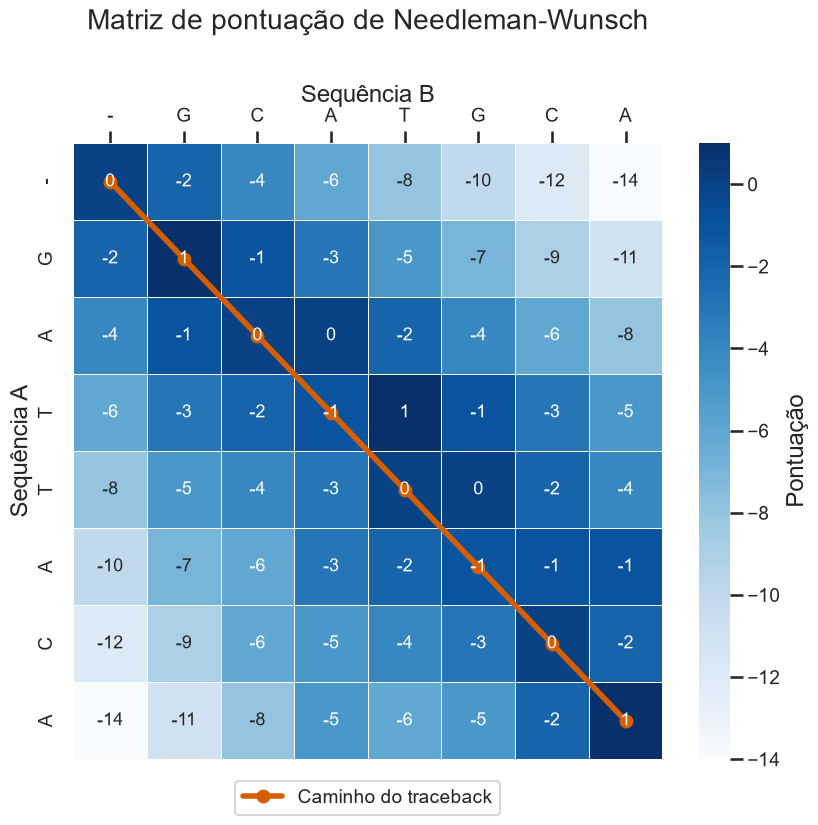

In [8]:
def plotar_matriz(F, a, b, caminho, arquivo=None):
    """Desenha a matriz de pontuação com os valores e o caminho do traceback destacado."""
    fig, ax = plt.subplots(figsize=(9.5, 8))
    sns.heatmap(F, annot=True, fmt="d", cmap="Blues", cbar_kws={"label": "Pontuação"},
                xticklabels=["-"] + list(b), yticklabels=["-"] + list(a),
                linewidths=0.5, linecolor="white", annot_kws={"size": 13}, ax=ax)
    ys, xs = zip(*caminho)
    ax.plot(np.array(xs) + 0.5, np.array(ys) + 0.5, color="#D55E00", lw=4, marker="o", ms=9, label="Caminho do traceback")
    ax.set_xlabel("Sequência B"); ax.set_ylabel("Sequência A")
    ax.set_title("Matriz de pontuação de Needleman-Wunsch", pad=40)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), frameon=True)
    ax.xaxis.tick_top(); ax.xaxis.set_label_position("top")
    if arquivo:
        fig.savefig(os.path.join(PASTA_FIGURAS, arquivo))
    plt.show()


# Teste 2: dois trechos curtos de DNA (match=+1, mismatch=-1, gap=-2)
seq_a, seq_b = "GATTACA", "GCATGCA"
F_ex, al_a, al_b, caminho, ident = alinhar(seq_a, seq_b)
mostrar_alinhamento(al_a, al_b)
print(f"Pontuação final: {F_ex[-1, -1]}   |   identidade: {ident:.1f}%")
plotar_matriz(F_ex, seq_a, seq_b, caminho, arquivo="01_matriz_needleman_wunsch.png")

### 3.2 Versão otimizada com NumPy
O algoritmo em Python puro faz ~1,3 milhão de cálculos por par de genes (1.140 × 1.140), e precisamos de **105 pares** (15 espécies). Dá para otimizar:

* **Vetorização por linhas.** Em cada linha `i` calculamos todas as colunas de uma vez com NumPy: a diagonal e o "vir de cima" dependem só da linha anterior, então viram operações de vetor.
* **O único problema** é o "vir da esquerda" (`F[i][j-1] + gap`), que depende da célula ao lado. Como o gap é linear, isso equivale a `F[i][j] = j·gap + máximo acumulado de (H[k] − k·gap)` para `k ≤ j`, onde `H` é o melhor entre diagonal e cima. Isso é um `np.maximum.accumulate`, que o NumPy executa em C.
* **Pré-computamos** o vetor de match/mismatch de cada letra (A, C, G, T) contra a sequência B, em vez de comparar caracteres um a um.

O resultado é **exatamente a mesma matriz** (verificamos abaixo), só que bem mais rápido. O traceback continua o mesmo, pois custa apenas O(n+m).

In [9]:
def nw_matriz_numpy(a, b, match=MATCH, mismatch=MISMATCH, gap=GAP):
    """Mesma matriz F do Needleman-Wunsch, mas calculada linha a linha com NumPy."""
    n, m = len(a), len(b)
    b_arr = np.frombuffer(b.encode(), dtype=np.uint8)
    # vetor de pontuação de cada letra contra todas as posições de B (calculado uma única vez)
    pont = {c: np.where(b_arr == ord(c), match, mismatch).astype(np.int32) for c in set(a)}
    kgap = np.arange(m + 1, dtype=np.int32) * gap          # [0, gap, 2*gap, ...]
    F = np.empty((n + 1, m + 1), dtype=np.int32)
    F[0] = kgap                                            # primeira linha: só buracos
    E = np.empty(m + 1, dtype=np.int32)
    for i in range(1, n + 1):
        E[0] = i * gap                                     # primeira coluna: só buracos
        E[1:] = np.maximum(F[i - 1, :-1] + pont[a[i - 1]], # diagonal (match/mismatch)
                           F[i - 1, 1:] + gap)             # vindo de cima
        # "vindo da esquerda" resolvido com máximo acumulado (substitui o laço interno)
        F[i] = np.maximum.accumulate(E - kgap) + kgap
    return F


def alinhar_rapido(a, b, match=MATCH, mismatch=MISMATCH, gap=GAP):
    """Mesmo que alinhar(), usando a matriz vetorizada."""
    F = nw_matriz_numpy(a, b, match, mismatch, gap)
    al_a, al_b, caminho = nw_traceback(F, a, b, match, mismatch, gap)
    return F, al_a, al_b, caminho, identidade(al_a, al_b)


# Verificação: as duas versões produzem a MESMA matriz (em exemplos curtos e em genes reais)
assert np.array_equal(nw_matriz_python(seq_a, seq_b), nw_matriz_numpy(seq_a, seq_b))
x, y = seqs[ordem[0]][:300], seqs[ordem[-1]][:300]
assert np.array_equal(nw_matriz_python(x, y), nw_matriz_numpy(x, y))
x, y = seqs[ordem[0]][:300], seqs[ordem[1]][:290]
assert np.array_equal(nw_matriz_python(x, y, 2, -3, -4), nw_matriz_numpy(x, y, 2, -3, -4))
print("OK: versão NumPy idêntica à versão em Python puro (inclusive com outros parâmetros de pontuação).")

OK: versão NumPy idêntica à versão em Python puro (inclusive com outros parâmetros de pontuação).


### 3.3 Validação contra o `PairwiseAligner` do Biopython
Configuramos o Biopython com a **mesma pontuação** (global, match +1, mismatch −1, gap −2 linear) e comparamos, em pares de genes completos:
* a **pontuação ótima** (deve ser idêntica; é o que prova que o algoritmo está correto);
* a **identidade percentual** (pode diferir um pouco, porque podem existir vários alinhamentos igualmente ótimos e cada programa escolhe um deles no desempate).

In [10]:
# Aligner do Biopython com a mesma pontuação do nosso algoritmo
aligner = Align.PairwiseAligner()
aligner.mode = "global"
aligner.match_score, aligner.mismatch_score = MATCH, MISMATCH
aligner.open_gap_score, aligner.extend_gap_score = GAP, GAP     # gap linear (igual ao nosso)

pares_teste = [("Humano", "Chimpanzé"), ("Humano", "Gorila"), ("Cachorro", "Lobo"),
               ("Gato", "Leão"), ("Baleia-azul", "Hipopótamo"), ("Humano", "Galinha"), ("Humano", "Peixe-zebra")]
pares_teste = [(p, q) for p, q in pares_teste if p in seqs and q in seqs]

linhas = []
for p, q in pares_teste:
    F, al_a, al_b, _, ident = alinhar_rapido(seqs[p], seqs[q])
    meu_score = int(F[-1, -1])
    bio_score = aligner.score(seqs[p], seqs[q])
    aln = aligner.align(seqs[p], seqs[q])[0]
    bio_ident = 100.0 * aln.counts().identities / aln.length
    linhas.append({"Par": f"{p} × {q}", "Score (meu)": meu_score, "Score (Biopython)": int(bio_score),
                   "Scores iguais?": meu_score == int(bio_score),
                   "Identidade % (meu)": round(ident, 2), "Identidade % (Biopython)": round(bio_ident, 2)})
comparacao = pd.DataFrame(linhas)
display(comparacao)
assert comparacao["Scores iguais?"].all(), "Pontuações divergem do Biopython!"
print("Validado: a pontuação ótima do meu algoritmo coincide com a do Biopython em todos os pares testados.")

# Mostra um alinhamento real (primeiras 120 colunas) para dar uma ideia de como fica
p, q = pares_teste[0]
_, al_a, al_b, _, ident = alinhar_rapido(seqs[p], seqs[q])
print(f"\nTrecho do alinhamento {p} × {q} (identidade total {ident:.1f}%):\n")
mostrar_alinhamento(al_a[:120], al_b[:120])

,Par,Score (meu),Score (Biopython),Scores iguais?,Identidade % (meu),Identidade % (Biopython)
0,Humano × Chimpanzé,885,885,True,88.88,88.88
1,Humano × Gorila,858,858,True,87.65,87.65
2,Cachorro × Lobo,1130,1130,True,99.56,99.56
3,Gato × Leão,846,846,True,87.11,87.11
4,Baleia-azul × Hipopótamo,704,704,True,81.00,81.00
5,Humano × Galinha,537,537,True,74.11,74.11
6,Humano × Peixe-zebra,451,451,True,70.18,70.18


Validado: a pontuação ótima do meu algoritmo coincide com a do Biopython em todos os pares testados.

Trecho do alinhamento Humano × Chimpanzé (identidade total 88.9%):

ATGACCCCAATACGCAAAACTAACCCCCTAATAAAATTAATTAACCACTCATTCATCGAC
|||||||||| |||||||| |||||| ||||||||||||||||| |||||||| ||||||
ATGACCCCAACACGCAAAATTAACCCACTAATAAAATTAATTAATCACTCATTTATCGAC

CTCCCCACCCCATCCAACATCTCCGCATGATGAAACTTCGGCTCACTCCTTGGCGCCTGC
|||||||||||||||||||| ||||||||||| ||||||||||| || || |||||||||
CTCCCCACCCCATCCAACATTTCCGCATGATGGAACTTCGGCTCCCTTCTCGGCGCCTGC



## 4. Análise: matriz de distância, heatmap e árvore

Para cada par de espécies:
1. alinhamos os genes (Needleman-Wunsch, versão NumPy);
2. calculamos a **identidade** (fração de colunas iguais no alinhamento);
3. definimos a **distância = 1 − identidade**. Quanto menor, mais parecidos os DNAs.

Só calculamos o triângulo superior (a distância de A a B é igual à de B a A) e espelhamos.

In [11]:
def matriz_distancia(seqs, nomes, alinhador=alinhar_rapido):
    """Distância = 1 - identidade para todos os pares (só triângulo superior; a matriz é simétrica)."""
    k = len(nomes)
    D = np.zeros((k, k))
    for i in range(k):
        for j in range(i + 1, k):
            *_, ident = alinhador(seqs[nomes[i]], seqs[nomes[j]])
            D[i, j] = D[j, i] = 1.0 - ident / 100.0
    return D


# Estimativa do ganho da otimização: tempo de UM par nas duas versões
a, b = seqs[ordem[0]], seqs[ordem[1]]
t0 = time.perf_counter(); alinhar(a, b); t_py = time.perf_counter() - t0
t0 = time.perf_counter(); alinhar_rapido(a, b); t_np = time.perf_counter() - t0
n_pares = len(ordem) * (len(ordem) - 1) // 2
print(f"Um par (~1.140 × 1.140 bases):  Python puro = {t_py:.2f} s   |   NumPy = {t_np:.3f} s   (≈ {t_py / t_np:.0f}x mais rápido)")
print(f"Para {n_pares} pares: Python puro ≈ {t_py * n_pares / 60:.1f} min   |   NumPy ≈ {t_np * n_pares:.0f} s")

t0 = time.perf_counter()
D = matriz_distancia(seqs, ordem)
print(f"\nMatriz de distância calculada em {time.perf_counter() - t0:.1f} s (versão NumPy).")

dist_df = pd.DataFrame(D, index=ordem, columns=ordem)
dist_df.to_csv(os.path.join(PASTA_DADOS, "matriz_distancia.csv"), float_format="%.4f")
display((dist_df * 100).round(1).style.background_gradient(cmap="viridis_r").format("{:.1f}"))

Um par (~1.140 × 1.140 bases):  Python puro = 0.18 s   |   NumPy = 0.010 s   (≈ 18x mais rápido)
Para 105 pares: Python puro ≈ 0.3 min   |   NumPy ≈ 1 s



Matriz de distância calculada em 1.1 s (versão NumPy).


,Humano,Chimpanzé,Gorila,Orangotango,Macaco-rhesus,Cachorro,Lobo,Gato,Leão,Vaca,Hipopótamo,Baleia-azul,Camundongo,Galinha,Peixe-zebra
Humano,0.0,11.1,12.3,16.0,19.7,25.3,24.9,22.7,24.8,26.4,24.8,26.4,24.4,25.9,29.8
Chimpanzé,11.1,0.0,12.4,15.0,19.0,24.8,24.5,23.2,24.8,25.1,24.5,26.5,23.8,26.1,30.4
Gorila,12.3,12.4,0.0,15.2,18.8,26.0,25.8,24.2,24.8,26.1,24.0,25.0,24.8,26.4,30.2
Orangotango,16.0,15.0,15.2,0.0,20.1,25.8,25.7,24.9,26.4,27.8,25.7,26.8,26.2,27.2,31.6
Macaco-rhesus,19.7,19.0,18.8,20.1,0.0,27.8,27.5,25.1,26.9,25.9,25.4,26.4,28.0,26.6,30.3
Cachorro,25.3,24.8,26.0,25.8,27.8,0.0,0.4,20.5,21.2,22.4,21.8,22.9,23.0,26.7,29.8
Lobo,24.9,24.5,25.8,25.7,27.5,0.4,0.0,20.6,21.2,22.2,21.4,22.6,22.9,26.4,29.8
Gato,22.7,23.2,24.2,24.9,25.1,20.5,20.6,0.0,12.9,20.1,21.1,22.4,20.8,26.2,28.5
Leão,24.8,24.8,24.8,26.4,26.9,21.2,21.2,12.9,0.0,21.9,22.1,23.1,22.6,27.8,28.6
Vaca,26.4,25.1,26.1,27.8,25.9,22.4,22.2,20.1,21.9,0.0,18.8,19.8,21.0,25.8,27.8


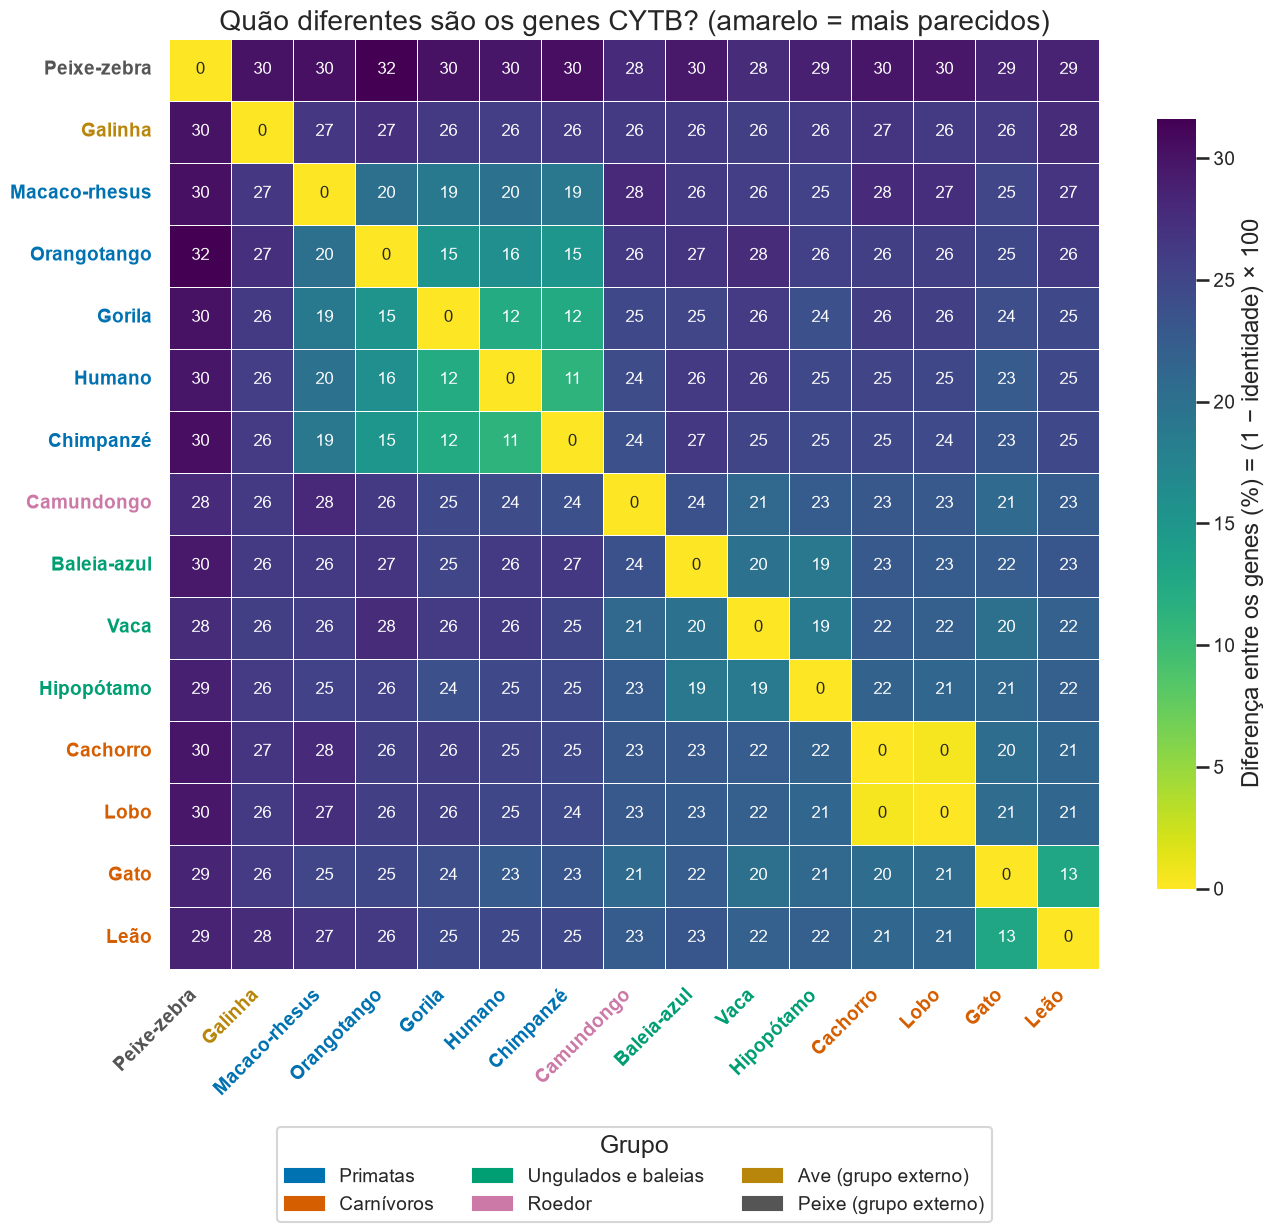

In [12]:
# ---------- UPGMA: linkage "average" do scipy ----------
# UPGMA = agrupar sempre os dois grupos mais próximos, usando a MÉDIA das distâncias entre os membros.
Z = linkage(squareform(D, checks=False), method="average")
folhas = dendrogram(Z, no_plot=True)["leaves"]          # ordem das espécies na árvore
ordem_arvore = [ordem[i] for i in folhas]

def colorir_rotulos(ax, eixo="y"):
    """Pinta o texto de cada espécie com a cor do seu grupo."""
    rotulos = ax.get_yticklabels() if eixo == "y" else ax.get_xticklabels()
    for r in rotulos:
        r.set_color(COR_GRUPO[GRUPO_DE[r.get_text()]]); r.set_fontweight("bold")

def legenda_grupos(ax, loc="lower right", **kw):
    grupos = [g for g in COR_GRUPO if g in {GRUPO_DE[n] for n in ordem}]
    ax.legend(handles=[Patch(color=COR_GRUPO[g], label=g) for g in grupos], loc=loc, frameon=True, title="Grupo", **kw)

# ---------- (a) Heatmap (espécies na ordem da árvore, para os blocos aparecerem) ----------
idx = [ordem.index(n) for n in ordem_arvore]
D_ord = D[np.ix_(idx, idx)] * 100
fig, ax = plt.subplots(figsize=(15, 12.5))
sns.heatmap(D_ord, annot=True, fmt=".0f", cmap="viridis_r", vmin=0, square=True,
            xticklabels=ordem_arvore, yticklabels=ordem_arvore, linewidths=0.4, linecolor="white",
            annot_kws={"size": 12}, cbar_kws={"label": "Diferença entre os genes (%) = (1 − identidade) × 100", "shrink": 0.8}, ax=ax)
ax.set_title("Quão diferentes são os genes CYTB? (amarelo = mais parecidos)")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
colorir_rotulos(ax, "x"); colorir_rotulos(ax, "y")
legenda_grupos(ax, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3)   # legenda fora da matriz
fig.savefig(os.path.join(PASTA_FIGURAS, "02_heatmap_distancias.png"))
plt.show()

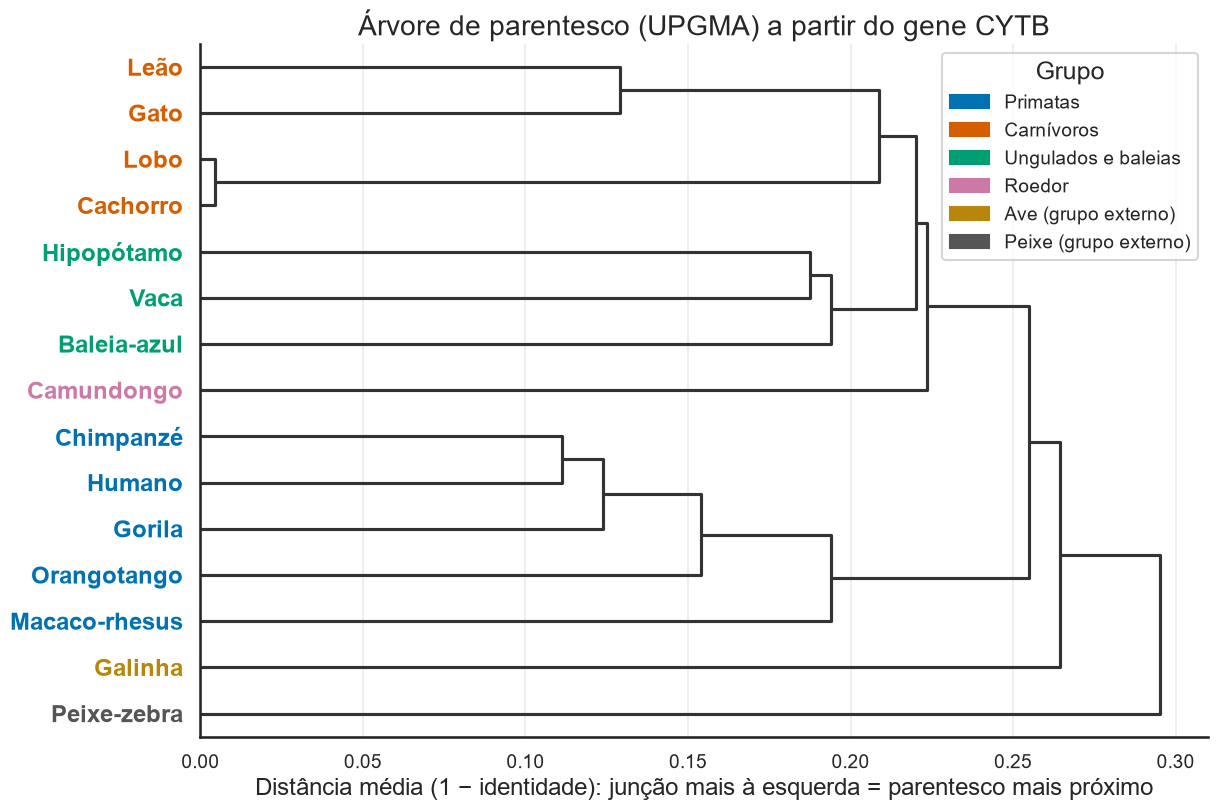

In [13]:
# ---------- (b) Árvore (dendrograma UPGMA) ----------
fig, ax = plt.subplots(figsize=(13, 9))
dendrogram(Z, labels=ordem, orientation="right", ax=ax, link_color_func=lambda k: "#333333", leaf_font_size=17)
ax.set_title("Árvore de parentesco (UPGMA) a partir do gene CYTB")
ax.set_xlabel("Distância média (1 − identidade): junção mais à esquerda = parentesco mais próximo")
colorir_rotulos(ax, "y")
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
ax.grid(axis="x", alpha=0.3)
legenda_grupos(ax, loc="upper right")
fig.savefig(os.path.join(PASTA_FIGURAS, "03_arvore_upgma.png"))
plt.show()

### O que esperávamos ver
Pela biologia já conhecida, esperamos que:
* **primatas** fiquem juntos (e, dentro deles, humano–chimpanzé–gorila mais próximos entre si);
* **felinos** (gato e leão) fiquem juntos e **canídeos** (cachorro e lobo) também, formando um grupo de carnívoros;
* a **baleia** fique perto do **hipopótamo** (os hipopótamos são os parentes vivos mais próximos das baleias!) e ambos perto da vaca;
* **galinha** e **peixe-zebra** (grupo externo) fiquem bem afastados dos mamíferos, com o peixe como o mais distante.

Vamos conferir isso de forma automática, perguntando para a árvore se cada grupo forma um ramo próprio (um *clado*).

In [14]:
def e_clado(Z, nomes, grupo):
    """True se as espécies do grupo formam um ramo exclusivo da árvore (e nenhuma outra espécie está nele)."""
    _, nos = to_tree(Z, rd=True)
    alvo = {nomes.index(n) for n in grupo}
    return any(set(no.pre_order()) == alvo for no in nos)

def vizinho_mais_proximo(nome):
    i = ordem.index(nome)
    d = D[i].copy(); d[i] = np.inf
    return ordem[int(np.argmin(d))], d.min()

testes = {
    "Primatas formam um ramo":                 [n for n in ordem if GRUPO_DE[n] == "Primatas"],
    "Humano + chimpanzé + gorila juntos":      ["Humano", "Chimpanzé", "Gorila"],
    "Gato + leão juntos (felinos)":            ["Gato", "Leão"],
    "Cachorro + lobo juntos (canídeos)":       ["Cachorro", "Lobo"],
    "Carnívoros formam um ramo":               [n for n in ordem if GRUPO_DE[n] == "Carnívoros"],
    "Baleia + hipopótamo juntos":              ["Baleia-azul", "Hipopótamo"],
    "Baleia + hipopótamo + vaca juntos":       ["Baleia-azul", "Hipopótamo", "Vaca"],
    "Todos os mamíferos formam um ramo (grupo externo fora)": [n for n in ordem if GRUPO_DE[n] not in ("Ave (grupo externo)", "Peixe (grupo externo)")],
}
print("Conferência da árvore com o esperado:\n")
for desc, grupo in testes.items():
    if len(grupo) >= 2 and all(n in ordem for n in grupo):
        print(f"  {'✔' if e_clado(Z, ordem, grupo) else '✘'}  {desc}")

print("\nVizinho mais próximo de cada espécie (menor distância):")
for n in ordem:
    v, d = vizinho_mais_proximo(n)
    print(f"  {n:14s} → {v:14s} (diferença de {d * 100:.1f}%)")

Conferência da árvore com o esperado:

  ✔  Primatas formam um ramo
  ✔  Humano + chimpanzé + gorila juntos
  ✔  Gato + leão juntos (felinos)
  ✔  Cachorro + lobo juntos (canídeos)
  ✔  Carnívoros formam um ramo
  ✘  Baleia + hipopótamo juntos
  ✔  Baleia + hipopótamo + vaca juntos
  ✔  Todos os mamíferos formam um ramo (grupo externo fora)

Vizinho mais próximo de cada espécie (menor distância):
  Humano         → Chimpanzé      (diferença de 11.1%)
  Chimpanzé      → Humano         (diferença de 11.1%)
  Gorila         → Humano         (diferença de 12.3%)
  Orangotango    → Chimpanzé      (diferença de 15.0%)
  Macaco-rhesus  → Gorila         (diferença de 18.8%)
  Cachorro       → Lobo           (diferença de 0.4%)
  Lobo           → Cachorro       (diferença de 0.4%)
  Gato           → Leão           (diferença de 12.9%)
  Leão           → Gato           (diferença de 12.9%)
  Vaca           → Hipopótamo     (diferença de 18.8%)
  Hipopótamo     → Vaca           (diferença de 18.8

### Interpretação: o resultado bateu?

**Em grande parte, sim:**
* ✔ **Primatas juntos**, e na ordem esperada: humano e chimpanzé são os mais próximos (~11% de diferença), depois o gorila, depois o orangotango e, por último, o macaco-rhesus.
* ✔ **Cachorro e lobo** quase idênticos (~0,4% de diferença, pois o cachorro é um lobo domesticado). **Gato e leão** formam o par de felinos, e os dois pares se juntam num ramo de **carnívoros**.
* ✔ **Galinha e peixe-zebra** (grupo externo) ficam fora do bloco dos mamíferos, com o peixe como o mais distante, como esperado.
* ✔ **Baleia, hipopótamo e vaca** formam um grupo próprio, e a baleia fica perto do hipopótamo.

**O que não bateu exatamente:**
* ✘ Na árvore, o hipopótamo se junta primeiro à **vaca** (18,8%) e só depois à baleia (19,0%). A diferença é minúscula (0,2 ponto percentual), então é praticamente um empate. Pela biologia, baleia + hipopótamo deveriam formar um par. Com um único gene e uma medida simples (porcentagem de letras iguais), a diferença entre essas duas hipóteses fica menor que o "ruído".
* ✘ O **camundongo** ficou junto dos carnívoros e ungulados, e não perto dos primatas, de quem é parente mais próximo. Os genes mitocondriais de roedores mudam muito rápido; com isso, ele acumulou muitas diferenças e acaba "se perdendo" na árvore. Além disso, em distâncias grandes (≥ 20%) mutações repetidas no mesmo ponto apagam parte do sinal evolutivo.

**Moral:** a árvore acerta bem os parentescos **recentes** (primatas, cães, felinos) e fica menos confiável nos **antigos**, onde um gene só e uma medida simples não bastam.

## 5. Complexidade: quanto tempo o algoritmo leva?

O preenchimento da matriz calcula **uma célula para cada par (i, j)**, e cada célula custa um número fixo de operações. Logo o tempo é proporcional a **n × m**, ou seja, **O(n·m)**. Com sequências do mesmo tamanho `n`, isso vira **O(n²)**: dobrar o tamanho deve **quadruplicar** o tempo.
(O traceback custa só O(n+m), desprezível perto do preenchimento; a memória também é O(n·m), por guardarmos a matriz inteira.)

Vamos medir: alinhamos prefixos de tamanhos crescentes (humano × vaca) e comparamos Python puro, NumPy e o Biopython (em C).

In [15]:
tamanhos = [100, 200, 400, 800, 1100]
tamanhos = [t for t in tamanhos if t <= min(len(s) for s in seqs.values())]
p, q = ("Humano", "Vaca") if {"Humano", "Vaca"} <= set(seqs) else (ordem[0], ordem[-1])

def melhor_tempo(f, repeticoes):
    """Menor tempo entre várias repetições (reduz o ruído de outros processos)."""
    ts = []
    for _ in range(repeticoes):
        t0 = time.perf_counter(); f(); ts.append(time.perf_counter() - t0)
    return min(ts)

res = []
for n in tamanhos:
    a, b = seqs[p][:n], seqs[q][:n]
    res.append({
        "n (bases)": n,
        "células (n·m)": n * n,
        "Python puro (s)": melhor_tempo(lambda: nw_matriz_python(a, b), 3 if n <= 400 else 2),
        "NumPy (s)":       melhor_tempo(lambda: nw_matriz_numpy(a, b), 5),
        "Biopython (s)":   melhor_tempo(lambda: aligner.score(a, b), 5),
    })
tempos = pd.DataFrame(res)
tempos["Python puro: µs por célula"] = tempos["Python puro (s)"] / tempos["células (n·m)"] * 1e6
display(tempos.style.format({"Python puro (s)": "{:.4f}", "NumPy (s)": "{:.4f}", "Biopython (s)": "{:.5f}",
                             "Python puro: µs por célula": "{:.3f}", "células (n·m)": "{:,}"}))
tempos.to_csv(os.path.join(PASTA_DADOS, "tempos_complexidade.csv"), index=False)

# Expoente empírico: inclinação da reta no gráfico log-log (tempo ~ n^expoente)
for col in ["Python puro (s)", "NumPy (s)", "Biopython (s)"]:
    expo = np.polyfit(np.log(tempos["n (bases)"]), np.log(tempos[col]), 1)[0]
    print(f"Expoente medido para {col:16s}: tempo ∝ n^{expo:.2f}")

,n (bases),células (n·m),Python puro (s),NumPy (s),Biopython (s),Python puro: µs por célula
0,100,"10,000",0.0012,0.0003,0.00002,0.121
1,200,"40,000",0.0052,0.0008,0.00007,0.129
2,400,"160,000",0.0220,0.0018,0.00027,0.137
3,800,"640,000",0.0994,0.0056,0.00108,0.155
4,1100,"1,210,000",0.1805,0.0087,0.00201,0.149


Expoente medido para Python puro (s) : tempo ∝ n^2.10
Expoente medido para NumPy (s)       : tempo ∝ n^1.38
Expoente medido para Biopython (s)   : tempo ∝ n^2.01


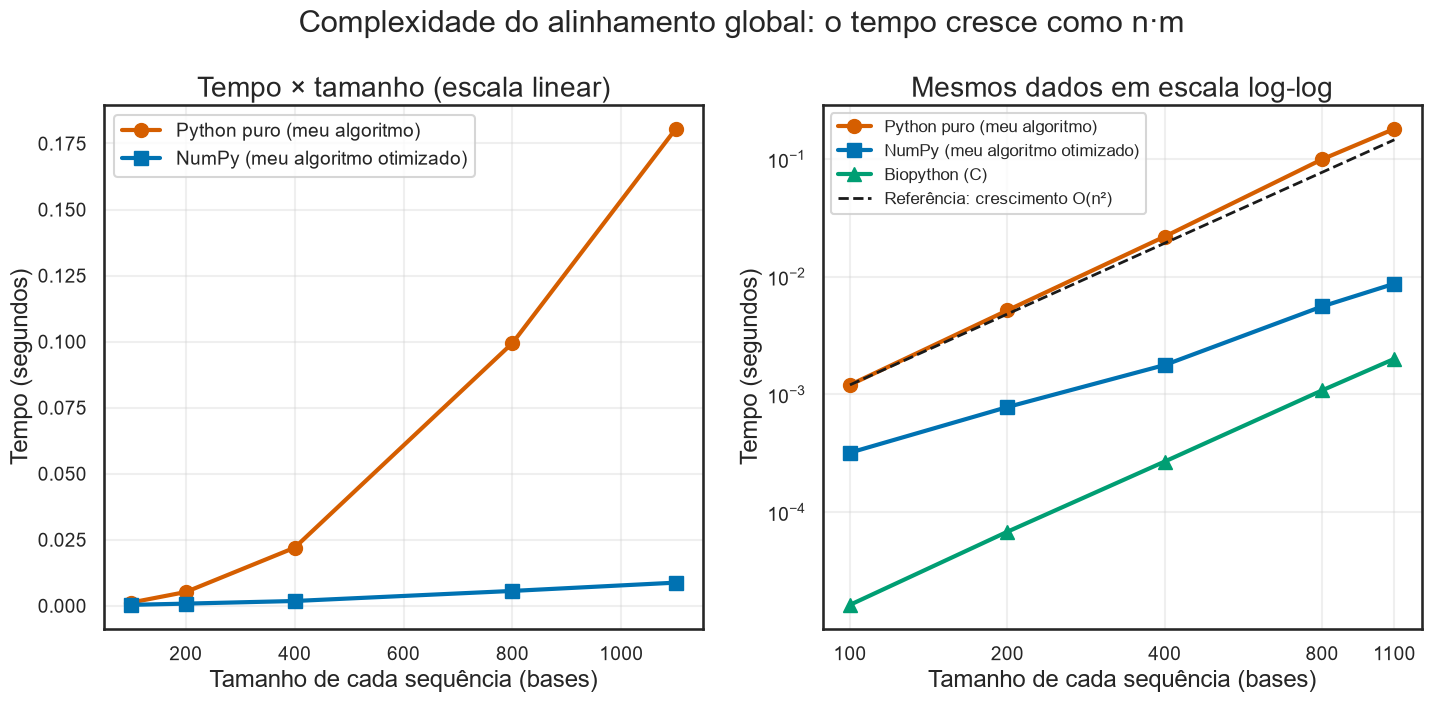

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6.8))
estilos = [("Python puro (s)", "#D55E00", "o", "Python puro (meu algoritmo)"),
           ("NumPy (s)",      "#0072B2", "s", "NumPy (meu algoritmo otimizado)"),
           ("Biopython (s)",  "#009E73", "^", "Biopython (C)")]

# Painel 1: escala linear, o "estouro" do Python puro
for col, cor, marc, rot in estilos[:2]:
    ax1.plot(tempos["n (bases)"], tempos[col], marker=marc, color=cor, lw=3, ms=10, label=rot)
ax1.set_title("Tempo × tamanho (escala linear)")
ax1.set_xlabel("Tamanho de cada sequência (bases)"); ax1.set_ylabel("Tempo (segundos)")
ax1.legend(); ax1.grid(alpha=0.3)

# Painel 2: log-log; uma reta de inclinação 2 significa O(n²) = O(n·m)
for col, cor, marc, rot in estilos:
    ax2.plot(tempos["n (bases)"], tempos[col], marker=marc, color=cor, lw=3, ms=10, label=rot)
n0, t0 = tempos["n (bases)"].iloc[0], tempos["Python puro (s)"].iloc[0]
ns = np.array(tempos["n (bases)"])
ax2.plot(ns, t0 * (ns / n0) ** 2, "k--", lw=2, label="Referência: crescimento O(n²)")
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xticks(tamanhos); ax2.set_xticklabels(tamanhos); ax2.minorticks_off()
ax2.set_title("Mesmos dados em escala log-log")
ax2.set_xlabel("Tamanho de cada sequência (bases)"); ax2.set_ylabel("Tempo (segundos)")
ax2.legend(fontsize=12); ax2.grid(alpha=0.3, which="both")
fig.suptitle("Complexidade do alinhamento global: o tempo cresce como n·m", fontsize=22, y=1.02)
fig.savefig(os.path.join(PASTA_FIGURAS, "04_complexidade_tempo.png"))
plt.show()

### O que as medições mostram
* **Python puro:** o expoente medido fica perto de **2** (a curva acompanha a linha tracejada O(n²) no gráfico log-log). Dobrar o tamanho multiplica o tempo por ~4, como a teoria prevê. O custo por célula (coluna "µs por célula") fica praticamente constante.
* **NumPy:** é muito mais rápido, mas o expoente medido é **menor que 2** (em torno de 1,3 a 1,4). Isso **não** significa que o algoritmo deixou de ser O(n·m): o trabalho total continua sendo n·m, só que agora feito em C, e para tamanhos pequenos o tempo é dominado pelo custo fixo de cada uma das n iterações do laço em Python (~O(n)). Com sequências bem maiores, a curva tenderia a se inclinar para 2.
* **Biopython:** é o mais rápido (implementado em C, sem a sobrecarga do Python). Nosso algoritmo em NumPy fica a poucas vezes de distância dele nos tamanhos de um gene, e o em Python puro quase duas ordens de grandeza.

**Por que isso importa?** Alinhar 15 espécies exige 105 pares, o que é tranquilo. Já alinhar, por exemplo, milhares de genomas inteiros (milhões de bases) com este algoritmo seria inviável: o custo O(n·m) explode. Por isso a bioinformática usa heurísticas e programas otimizados.

## 6. Conclusões e limitações

1. Comparar o DNA funciona como "régua de parentesco": quanto mais parecidos os genes, mais próximos os animais. Nossa árvore reencontrou os grupos conhecidos: primatas, felinos, cães, e os mamíferos separados da galinha e do peixe.
2. O algoritmo de Needleman-Wunsch, implementado do zero, deu **exatamente a mesma pontuação** que o Biopython em todos os pares testados, e o NumPy o tornou muito mais rápido, mantendo o resultado idêntico.
3. O tempo cresce como n·m: dobrar o tamanho das sequências quadruplica o tempo, o que limita o uso em dados gigantes.
4. **Limitações:** um único gene (CYTB) não conta toda a história evolutiva; ele é do DNA mitocondrial, herdado só da mãe, e muda em ritmos diferentes em cada linhagem (o camundongo e o par hipopótamo-baleia ficaram fora do esperado).
5. Além disso, usamos só a identidade simples (sem corrigir mutações repetidas) e o UPGMA, que assume que todas as linhagens evoluem na mesma velocidade. Estudos sérios usam muitos genes e métodos mais sofisticados.
6. Sobre os dados: para humano, gorila, camundongo e peixe-zebra o CYTB foi extraído de genomas mitocondriais de referência; os demais vêm de registros do gene, com 1.140 a 1.144 bases em todas as espécies.

In [17]:
# Resumo dos arquivos gerados
print("Arquivos gerados:")
for pasta in (PASTA_DADOS, PASTA_FIGURAS):
    for f in sorted(os.listdir(pasta)):
        print(f"  {pasta}/{f}  ({os.path.getsize(os.path.join(pasta, f)) / 1024:.0f} KB)")
print(f"\nFonte dos dados desta execução: {FONTE}")

Arquivos gerados:
  dados/cytb_especies.fasta  (18 KB)
  dados/matriz_distancia.csv  (2 KB)
  dados/tempos_complexidade.csv  (1 KB)
  figuras/01_matriz_needleman_wunsch.png  (151 KB)
  figuras/02_heatmap_distancias.png  (463 KB)
  figuras/03_arvore_upgma.png  (161 KB)
  figuras/04_complexidade_tempo.png  (260 KB)

Fonte dos dados desta execução: NCBI
